# 06 — Retraining Strategies: Static vs Scheduled vs Drift-Triggered

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Simulate three retraining strategies over rolling 7-day windows on IEEE-CIS and compare operational metrics
**Outputs**: `reports/retraining_strategy_comparison.csv`, `reports/retraining_detailed_results.csv`, `reports/retraining_events.csv` (consumed by 07_evaluation.ipynb)

In [1]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

from data_prep import load_ieee_cis, handle_class_imbalance
from models import get_model, train_model, evaluate_model, save_model, load_model
from drift_detection import DriftMonitor, should_retrain_from_drift
from evaluation import compute_operational_metrics, compare_strategies_statistically

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(exist_ok=True)

print(f'Data root: {DATA_ROOT.absolute()}')

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load Data & Initial Model

In [2]:
# Load IEEE-CIS full data (time-ordered)
ieee_df = load_ieee_cis(DATA_ROOT / 'ieee-cis')
print(f'IEEE-CIS loaded: {ieee_df.shape}')

def apply_fe(df, name):
    df = df.copy()
    if name == 'ieee-cis':
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        df['day'] = (df['TransactionDT'] // 86400).astype(int)  # matches 01_eda splits
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    return df

ieee_df = apply_fe(ieee_df, 'ieee-cis')

def prepare_xy(df):
    drop_cols = ['TransactionID', 'TransactionDT', 'isFraud']
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['isFraud'].astype('int8') if 'isFraud' in df.columns else None
    for col in X.select_dtypes(exclude=['number']).columns:
        X[col] = X[col].astype('category').cat.codes
    return X.fillna(-999), y

X_all, y_all = prepare_xy(ieee_df)

# Load initial model (trained in 02_baselines); train one if missing
model_path = MODELS_DIR / 'ieee_lightgbm.joblib'
if model_path.exists():
    model, meta = load_model(model_path)
    print(f'Loaded initial model: {(meta or {}).get("model", "lightgbm")}')
else:
    print('Saved model not found — training initial LightGBM on train split')
    train_ieee = pd.read_parquet(DATA_ROOT / 'ieee-cis' / 'splits' / 'train.parquet')
    train_ieee = apply_fe(train_ieee, 'ieee-cis')
    X_tr, y_tr = prepare_xy(train_ieee)
    params = handle_class_imbalance(X_tr, y_tr)
    model = train_model(get_model('lightgbm', params), X_tr, y_tr)
    save_model(model, model_path, {'model': 'lightgbm', 'note': 'initial'})

# Align features to the model (order + missing/extra columns)
feature_names = list(model.feature_name_)
X_all = X_all.reindex(columns=feature_names, fill_value=-999)
print(f'Features aligned to model: {X_all.shape[1]}')

# Initial risk scores — used as the drift reference distribution
ieee_df['risk_score'] = model.predict_proba(X_all)[:, 1]
print(f'Day range: {ieee_df["day"].min()} - {ieee_df["day"].max()}')

IEEE-CIS loaded: (590540, 394)
Loaded initial model: lightgbm
Features aligned to model: 397
Day range: 1 - 182


## 2. Simulation Setup

In [3]:
# Simulation constants
TRAIN_WINDOW_DAYS = 30
TEST_WINDOW_DAYS = 7
START_DAY = 30               # initial model treated as fresh at day 30
MAX_TRAIN_SAMPLES = 100_000  # cap retraining set to most recent N rows (speed)
PSI_THRESHOLD = 0.2
KS_THRESHOLD = 0.05

max_day = int(ieee_df['day'].max())

# Features to monitor for drift (top 30 numeric)
num_features = X_all.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = num_features[:30]

# Drift monitor fitted on reference window (days 0-29) with initial model scores
ref_data = ieee_df[ieee_df['day'] < START_DAY].copy()
monitor = DriftMonitor(psi_threshold=PSI_THRESHOLD, ks_threshold=KS_THRESHOLD)
monitor.fit(ref_data, feature_cols, score_col='risk_score')
print(f'DriftMonitor fitted: {len(ref_data):,} reference rows, {len(feature_cols)} features')

def train_fresh_lightgbm(X_tr, y_tr, X_val, y_val):
    params = handle_class_imbalance(X_tr, y_tr, method='class_weight')
    m = get_model('lightgbm', params)
    return train_model(m, X_tr, y_tr, X_val, y_val)

DriftMonitor fitted: 130,968 reference rows, 30 features


## 3. Run Strategy Simulation

Each strategy starts from the same initial model. Per 7-day window: evaluate the current model, then decide whether to retrain (retraining uses the trailing 30-day window, so there is no leakage into the current test window).

In [4]:
def run_strategy(strategy_name, initial_model):
    model = initial_model
    last_retrain_day = START_DAY
    detailed_rows = []
    events = []

    windows = list(range(START_DAY, max_day - TEST_WINDOW_DAYS + 1, TEST_WINDOW_DAYS))
    print(f'\n=== Strategy: {strategy_name} ({len(windows)} windows) ===')

    for ws in windows:
        we = ws + TEST_WINDOW_DAYS
        window_data = ieee_df[(ieee_df['day'] >= ws) & (ieee_df['day'] < we)]
        if len(window_data) == 0:
            continue

        X_win, y_win = prepare_xy(window_data)
        X_win = X_win.reindex(columns=model.feature_name_, fill_value=-999)
        y_win = y_win.values

        scores = model.predict_proba(X_win)[:, 1]
        metrics = evaluate_model(model, X_win, pd.Series(y_win))
        op = compute_operational_metrics(y_win, scores, total_transactions=len(y_win))
        model_age = ws - last_retrain_day

        # Decide retraining for THIS window (model update applies from next window)
        retrained = False
        trigger = 'none'
        if strategy_name == 'scheduled_7d':
            if model_age >= 7:
                retrained, trigger = True, 'scheduled'
        elif strategy_name == 'drift_triggered':
            wd = window_data.copy()
            wd['risk_score'] = scores
            drift_result = monitor.check(wd, timestamp=f'day_{ws}_{we}')
            should, reason = should_retrain_from_drift(drift_result, PSI_THRESHOLD, KS_THRESHOLD)
            if should:
                retrained, trigger = True, reason

        detailed_rows.append({
            'strategy': strategy_name,
            'window_start': ws,
            'window_end': we,
            'retrained': retrained,
            'trigger': trigger,
            'model_age_days': model_age,
            'pr_auc': metrics['pr_auc'],
            'roc_auc': metrics['roc_auc'],
            'precision_at_100': metrics.get('precision_at_100', 0),
            'recall_at_100': metrics.get('recall_at_100', 0),
            'fp_per_100k_at_budget_100': op.get('fp_per_100k_at_budget_100', 0),
        })

        if retrained:
            train_data = ieee_df[(ieee_df['day'] >= ws - TRAIN_WINDOW_DAYS) & (ieee_df['day'] < ws)]
            if len(train_data) >= 1000:
                if len(train_data) > MAX_TRAIN_SAMPLES:
                    train_data = train_data.tail(MAX_TRAIN_SAMPLES)
                X_tr_all, y_tr_all = prepare_xy(train_data)
                split_idx = int(len(X_tr_all) * 0.8)
                X_tr, y_tr = X_tr_all.iloc[:split_idx], y_tr_all.iloc[:split_idx]
                X_val, y_val = X_tr_all.iloc[split_idx:], y_tr_all.iloc[split_idx:]
                model = train_fresh_lightgbm(X_tr, y_tr, X_val, y_val)
                last_retrain_day = ws
                events.append({
                    'strategy': strategy_name,
                    'day': ws,
                    'trigger': trigger,
                    'model_age_days': model_age,
                    'train_samples': len(X_tr_all),
                })
                print(f'  day {ws}-{we}: RETRAIN ({trigger}), age={model_age}d, samples={len(X_tr_all):,}')

    return detailed_rows, events

detailed_all = []
events_all = []
for strat in ['static', 'scheduled_7d', 'drift_triggered']:
    rows, evs = run_strategy(strat, model)
    detailed_all.extend(rows)
    events_all.extend(evs)

detailed_df = pd.DataFrame(detailed_all)
events_df = pd.DataFrame(events_all)
print(f'\nDetailed results: {detailed_df.shape}, retrain events: {events_df.shape}')


=== Strategy: static (21 windows) ===

=== Strategy: scheduled_7d (21 windows) ===
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[4]	valid_0's auc: 0.921692
  day 37-44: RETRAIN (scheduled), age=7d, samples=100,000
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[4]	valid_0's auc: 0.923319
  day 44-51: RETRAIN (scheduled), age=7d, samples=100,000
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[43]	valid_0's auc: 0.916626
  day 51-58: RETRAIN (scheduled), age=7d, samples=100,000
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[5]	valid_0's auc: 0.916529
  day 58-65: RETRAIN (scheduled), age=7d, samples=92,389
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[104]	valid_0's auc: 0.950035
  day 65-72: RETRAIN (scheduled), age=7d, samples=90,823
Train

## 4. Strategy Comparison Summary

Aggregates per strategy and saves the two CSVs that notebook 07 loads.

In [5]:
summary_rows = []
for strat, grp in detailed_df.groupby('strategy'):
    ev = events_df[events_df['strategy'] == strat] if not events_df.empty else pd.DataFrame()
    summary_rows.append({
        'strategy': strat,
        'n_windows': len(grp),
        'pr_auc_mean': grp['pr_auc'].mean(),
        'pr_auc_std': grp['pr_auc'].std(),
        'roc_auc_mean': grp['roc_auc'].mean(),
        'precision_at_100_mean': grp['precision_at_100'].mean(),
        'recall_at_100_mean': grp['recall_at_100'].mean(),
        'fp_per_100k_mean': grp['fp_per_100k_at_budget_100'].mean(),
        'retrain_count': len(ev),
        'avg_model_age_days': grp['model_age_days'].mean(),
        'max_model_age_days': grp['model_age_days'].max(),
    })
comparison_df = pd.DataFrame(summary_rows)
print('=== Strategy Comparison ===')
display(comparison_df)

comparison_df.to_csv(REPORTS_DIR / 'retraining_strategy_comparison.csv', index=False)
detailed_df.to_csv(REPORTS_DIR / 'retraining_detailed_results.csv', index=False)
if not events_df.empty:
    events_df.to_csv(REPORTS_DIR / 'retraining_events.csv', index=False)
print(f'Saved to {REPORTS_DIR}: retraining_strategy_comparison.csv, retraining_detailed_results.csv')

=== Strategy Comparison ===


,strategy,n_windows,pr_auc_mean,pr_auc_std,roc_auc_mean,precision_at_100_mean,recall_at_100_mean,fp_per_100k_mean,retrain_count,avg_model_age_days,max_model_age_days
0,drift_triggered,21,0.486903,0.092058,0.894137,0.840476,1.0,236.904835,21,6.666667,7
1,scheduled_7d,21,0.491770,0.097642,0.894735,0.845238,1.0,233.723263,20,6.666667,7
2,static,21,0.548540,0.092754,0.897205,0.951905,1.0,24.386866,0,70.000000,140


Saved to ../reports: retraining_strategy_comparison.csv, retraining_detailed_results.csv


## 5. Statistical Significance (Wilcoxon signed-rank on paired windows)

In [6]:
stat_comp = compare_strategies_statistically(detailed_df, metric='pr_auc')
print('=== Statistical comparison (PR-AUC, paired by window) ===')
for comp, res in stat_comp.items():
    sig = 'SIGNIFICANT' if res['significant'] else 'not significant'
    print(f'  {comp}: mean_diff={res["mean_diff"]:.4f}, p={res["p_value"]:.4f} ({sig})')

=== Statistical comparison (PR-AUC, paired by window) ===
  static_vs_scheduled_7d: mean_diff=0.0568, p=0.0001 (SIGNIFICANT)
  static_vs_drift_triggered: mean_diff=0.0616, p=0.0001 (SIGNIFICANT)
  scheduled_7d_vs_drift_triggered: mean_diff=0.0049, p=0.3173 (not significant)


## 6. Visualizations

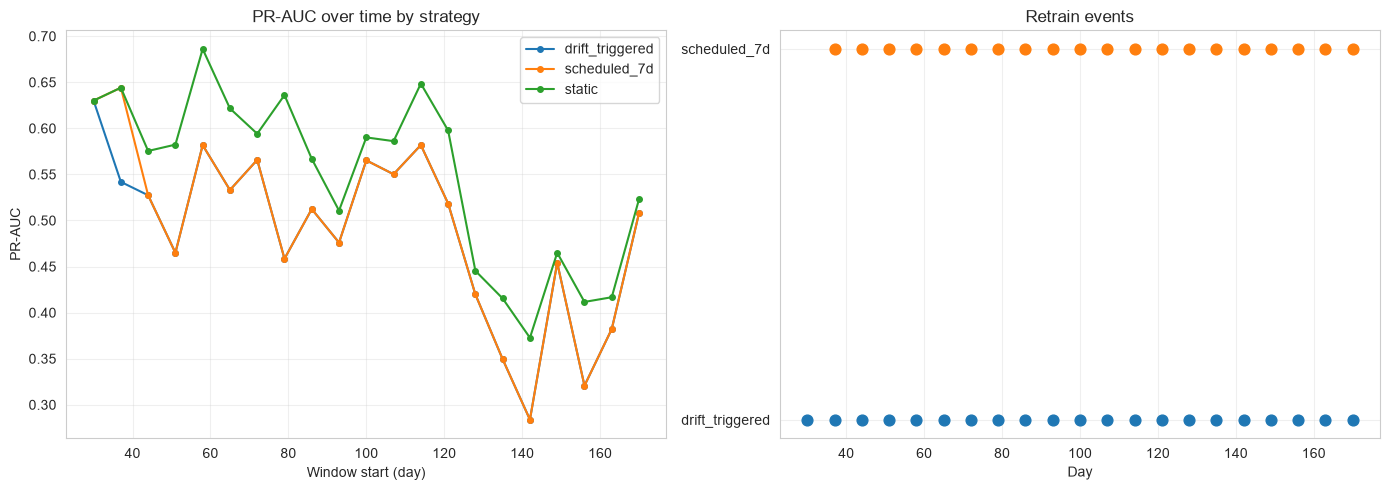

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for strat, grp in detailed_df.groupby('strategy'):
    axes[0].plot(grp['window_start'], grp['pr_auc'], marker='o', markersize=4, label=strat)
axes[0].set_xlabel('Window start (day)')
axes[0].set_ylabel('PR-AUC')
axes[0].set_title('PR-AUC over time by strategy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if not events_df.empty:
    for strat, grp in events_df.groupby('strategy'):
        axes[1].scatter(grp['day'], [strat] * len(grp), s=60, label=strat)
axes[1].set_xlabel('Day')
axes[1].set_title('Retrain events')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Summary & Next Steps

In [8]:
best = comparison_df.loc[comparison_df['pr_auc_mean'].idxmax()]
print(f'''
=== RETRAINING STRATEGY COMPARISON COMPLETE ===

Strategies simulated: static, scheduled_7d, drift_triggered
Best PR-AUC: {best["strategy"]} ({best["pr_auc_mean"]:.4f} +/- {best["pr_auc_std"]:.4f})
Retrain counts: {dict(zip(comparison_df["strategy"], comparison_df["retrain_count"]))}

Saved: reports/retraining_strategy_comparison.csv
       reports/retraining_detailed_results.csv
       reports/retraining_events.csv

NEXT: 07_evaluation.ipynb (section 7 now has its inputs)
''')


=== RETRAINING STRATEGY COMPARISON COMPLETE ===

Strategies simulated: static, scheduled_7d, drift_triggered
Best PR-AUC: static (0.5485 +/- 0.0928)
Retrain counts: {'drift_triggered': 21, 'scheduled_7d': 20, 'static': 0}

Saved: reports/retraining_strategy_comparison.csv
       reports/retraining_detailed_results.csv
       reports/retraining_events.csv

NEXT: 07_evaluation.ipynb (section 7 now has its inputs)

